# Systems of Equations — From Hyperplanes to Solvers

> Every exact solve, every least-squares fit, every Newton step, and every constrained update in AI is a system-of-equations problem in disguise.

This notebook is the interactive companion to [notes.md](notes.md). It is intentionally arranged as a **learning path** rather than a section-by-section copy of the note.

| Block | Topic | What you will build |
|---|---|---|
| 1 | Geometry and rank | classify unique / infinite / inconsistent systems |
| 2 | Row operations | manipulate augmented matrices and compute RREF |
| 3 | Solution structure | recover particular solutions and null-space directions |
| 4 | Least squares | derive normal equations and verify residual orthogonality |
| 5 | Stability | measure condition numbers and sensitivity to perturbations |
| 6 | Iterative solvers | compare Jacobi, Gauss-Seidel, and conjugate gradient |
| 7 | Nonlinear systems | run Newton's method on a coupled nonlinear problem |
| 8 | Constraints | solve a small KKT saddle-point system |
| 9 | AI views | attention weights, fixed points, and tiny GP solves |

This notebook was shaped using the local course style plus public materials from MIT 18.06, Stanford EE263, Netlib's *Templates for the Solution of Linear Systems*, public numerical linear algebra notebook resources, and the repository notation / chapter guides.

---


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

try:
    import seaborn as sns
    sns.set_theme(style="whitegrid", palette="colorblind")
    HAS_SNS = True
except ImportError:
    plt.style.use("seaborn-v0_8-whitegrid")
    HAS_SNS = False

mpl.rcParams.update({
    "figure.figsize":    (10, 6),
    "figure.dpi":         120,
    "font.size":           13,
    "axes.titlesize":      15,
    "axes.labelsize":      13,
    "xtick.labelsize":     11,
    "ytick.labelsize":     11,
    "legend.fontsize":     11,
    "legend.framealpha":   0.85,
    "lines.linewidth":      2.0,
    "axes.spines.top":     False,
    "axes.spines.right":   False,
    "savefig.bbox":       "tight",
    "savefig.dpi":         150,
})
np.random.seed(42)
print("Plot setup complete.")

Plot setup complete.


In [2]:
import numpy as np
import numpy.linalg as la
import scipy.linalg as sla
from scipy import stats

COLORS = {
    "primary": "#0077BB",
    "secondary": "#EE7733",
    "tertiary": "#009988",
    "error": "#CC3311",
    "neutral": "#555555",
    "highlight": "#EE3377",
}
HAS_MPL = True
np.set_printoptions(precision=8, suppress=True)
np.random.seed(42)

def header(title):
    print("\n" + "=" * len(title))
    print(title)
    print("=" * len(title))

def check_true(name, cond):
    ok = bool(cond)
    print(f"{'PASS' if ok else 'FAIL'} - {name}")
    return ok

def check_close(name, got, expected, tol=1e-8):
    ok = np.allclose(got, expected, atol=tol, rtol=tol)
    print(f"{'PASS' if ok else 'FAIL'} - {name}: got {got}, expected {expected}")
    return ok

def check(name, got, expected, tol=1e-8):
    return check_close(name, got, expected, tol=tol)

def softmax(z, axis=-1, tau=1.0):
    z = np.asarray(z, dtype=float) / float(tau)
    z = z - np.max(z, axis=axis, keepdims=True)
    e = np.exp(z)
    return e / np.sum(e, axis=axis, keepdims=True)

def cosine_similarity(a, b):
    a = np.asarray(a, dtype=float); b = np.asarray(b, dtype=float)
    return float(a @ b / (la.norm(a) * la.norm(b) + 1e-12))

def numerical_rank(A, tol=1e-10):
    return int(np.sum(la.svd(A, compute_uv=False) > tol))

def orthonormal_basis(A, tol=1e-10):
    Q, R = la.qr(A)
    keep = np.abs(np.diag(R)) > tol
    return Q[:, keep]

def null_space(A, tol=1e-10):
    U, S, Vt = la.svd(A)
    return Vt[S.size:,:].T if S.size < Vt.shape[0] else Vt[S <= tol,:].T



# Compatibility helpers used by the Chapter 02 theory and exercise cells.
def null_space(A, tol=1e-10):
    A = np.asarray(A, dtype=float)
    U, S, Vt = la.svd(A, full_matrices=True)
    rank = int(np.sum(S > tol))
    return Vt[rank:].T

svd_null_space = null_space

def gram_schmidt(vectors, tol=1e-10):
    A = np.asarray(vectors, dtype=float)
    if A.ndim == 1:
        A = A.reshape(1, -1)
    basis = []
    for v in A:
        w = v.astype(float).copy()
        for q in basis:
            w = w - np.dot(w, q) * q
        norm = la.norm(w)
        if norm > tol:
            basis.append(w / norm)
    return np.array(basis)

def projection_matrix_from_columns(A, tol=1e-10):
    Q = orthonormal_basis(np.asarray(A, dtype=float), tol=tol)
    return Q @ Q.T


def random_unit_vectors(n, d):
    X = np.random.randn(n, d)
    return X / np.maximum(la.norm(X, axis=1, keepdims=True), 1e-12)

def pairwise_distances(X):
    X = np.asarray(X, dtype=float)
    diff = X[:, None, :] - X[None, :, :]
    return la.norm(diff, axis=-1)


def normalize(x, axis=None, tol=1e-12):
    x = np.asarray(x, dtype=float)
    norm = la.norm(x, axis=axis, keepdims=True)
    return x / np.maximum(norm, tol)

def frobenius_inner(A, B):
    return float(np.sum(np.asarray(A, dtype=float) * np.asarray(B, dtype=float)))

def outer_sum_product(A, B):
    A = np.asarray(A, dtype=float)
    B = np.asarray(B, dtype=float)
    return sum(np.outer(A[:, k], B[k, :]) for k in range(A.shape[1]))

def softmax_rows(X):
    return softmax(X, axis=1)

def col_space(A, tol=1e-10):
    return orthonormal_basis(np.asarray(A, dtype=float), tol=tol)

def row_space(A, tol=1e-10):
    return orthonormal_basis(np.asarray(A, dtype=float).T, tol=tol).T

def rref(A, tol=1e-10):
    R = np.array(A, dtype=float, copy=True)
    m, n = R.shape
    pivots = []
    row = 0
    for col in range(n):
        pivot = row + int(np.argmax(np.abs(R[row:, col]))) if row < m else row
        if row >= m or abs(R[pivot, col]) <= tol:
            continue
        if pivot != row:
            R[[row, pivot]] = R[[pivot, row]]
        R[row] = R[row] / R[row, col]
        for r in range(m):
            if r != row:
                R[r] = R[r] - R[r, col] * R[row]
        pivots.append(col)
        row += 1
        if row == m:
            break
    R[np.abs(R) < tol] = 0.0
    return R, pivots

def nullspace_basis(A, tol=1e-10):
    A = np.asarray(A, dtype=float)
    U, S, Vt = la.svd(A, full_matrices=True)
    rank = int(np.sum(S > tol))
    return Vt[rank:].T, rank

print("Chapter helper setup complete.")



Chapter helper setup complete.


---

## 1. Geometry, Rank, and the Three Cases

A system $Ax=b$ is really asking one question:

$$
\text{Does } b \text{ lie in the column space of } A?
$$

That question splits into three cases:

- **unique solution**: consistent and no free directions remain
- **infinitely many solutions**: consistent, but some directions remain unconstrained
- **no solution**: the right-hand side points outside the achievable column space

The quickest computational summary is:

$$\operatorname{rank}(A) \overset{?}{=} \operatorname{rank}([A\mid b]).$$

---

## 1. Classifying Systems by Rank


In [3]:
# ======================================================================
# 1.1 Classify systems by rank
# ======================================================================

def classify_system(A, b):
    A = np.array(A, dtype=float)
    b = np.array(b, dtype=float).reshape(-1, 1)
    aug = np.hstack([A, b])
    rank_A = np.linalg.matrix_rank(A)
    rank_aug = np.linalg.matrix_rank(aug)
    n = A.shape[1]

    if rank_A < rank_aug:
        label = 'inconsistent'
    elif rank_A == n:
        label = 'unique'
    else:
        label = 'infinitely many'

    return {
        'rank(A)': rank_A,
        'rank([A|b])': rank_aug,
        'unknowns': n,
        'type': label,
    }


examples = {
    'unique': (
        np.array([[1, 2], [3, 4]], dtype=float),
        np.array([5, 11], dtype=float),
    ),
    'infinite': (
        np.array([[1, 2], [2, 4]], dtype=float),
        np.array([3, 6], dtype=float),
    ),
    'inconsistent': (
        np.array([[1, 1], [1, 1]], dtype=float),
        np.array([2, 3], dtype=float),
    ),
}

for name, (A, b) in examples.items():
    summary = classify_system(A, b)
    print(f"{name.upper():<12} -> {summary}")

UNIQUE       -> {'rank(A)': np.int64(2), 'rank([A|b])': np.int64(2), 'unknowns': 2, 'type': 'unique'}
INFINITE     -> {'rank(A)': np.int64(1), 'rank([A|b])': np.int64(1), 'unknowns': 2, 'type': 'infinitely many'}
INCONSISTENT -> {'rank(A)': np.int64(1), 'rank([A|b])': np.int64(2), 'unknowns': 2, 'type': 'inconsistent'}


---

## 2. Matrix Form and Augmented Matrices

In theory, $Ax=b$ is compact notation. In practice, the **augmented matrix** $[A\mid b]$ is what we manipulate during elimination.

The three elementary row operations preserve the solution set:

1. swap two rows
2. scale a row by a non-zero scalar
3. add a multiple of one row to another

This is the algebraic engine behind Gaussian elimination.

---

## 2. Gaussian Elimination — Row Operations


In [4]:
# ======================================================================
# 2.1 Elementary row operations on an augmented matrix
# ======================================================================

def augment(A, b):
    A = np.array(A, dtype=float)
    b = np.array(b, dtype=float).reshape(-1, 1)
    return np.hstack([A, b])


def swap_rows(M, i, j):
    M = M.copy()
    M[[i, j]] = M[[j, i]]
    return M


def scale_row(M, i, alpha):
    M = M.copy()
    M[i] *= alpha
    return M


def add_multiple(M, target, source, alpha):
    M = M.copy()
    M[target] += alpha * M[source]
    return M


M = augment([[1, 2, 1], [2, -1, 3], [3, 1, -1]], [9, 8, 3])
print('Initial [A|b]:\n', M)
print('\nSwap R1 and R3:')
print(swap_rows(M, 0, 2))
print('\nScale R1 by 1/3:')
print(scale_row(M, 0, 1/3))
print('\nR2 <- R2 - 2R1:')
print(add_multiple(M, 1, 0, -2))

Initial [A|b]:
 [[ 1.  2.  1.  9.]
 [ 2. -1.  3.  8.]
 [ 3.  1. -1.  3.]]

Swap R1 and R3:
[[ 3.  1. -1.  3.]
 [ 2. -1.  3.  8.]
 [ 1.  2.  1.  9.]]

Scale R1 by 1/3:
[[ 0.33333333  0.66666667  0.33333333  3.        ]
 [ 2.         -1.          3.          8.        ]
 [ 3.          1.         -1.          3.        ]]

R2 <- R2 - 2R1:
[[  1.   2.   1.   9.]
 [  0.  -5.   1. -10.]
 [  3.   1.  -1.   3.]]


---

## 3. Gaussian Elimination and RREF

Row-echelon form reveals pivots and free variables. Reduced row-echelon form goes further: it exposes the solution structure directly.

We will implement a small RREF routine manually. This is not meant to outperform `numpy` or LAPACK. It is for understanding exactly how elimination reveals rank and solution geometry.

---

## 3. Reduced Row Echelon Form (RREF)


In [5]:
# ======================================================================
# 3.1 Manual RREF with partial pivoting
# ======================================================================

def rref(M, tol=1e-12):
    M = np.array(M, dtype=float).copy()
    rows, cols = M.shape
    pivot_cols = []
    r = 0

    for c in range(cols):
        if r >= rows:
            break

        pivot = r + np.argmax(np.abs(M[r:, c]))
        if abs(M[pivot, c]) < tol:
            continue

        if pivot != r:
            M[[r, pivot]] = M[[pivot, r]]

        M[r] = M[r] / M[r, c]

        for i in range(rows):
            if i != r and abs(M[i, c]) > tol:
                M[i] -= M[i, c] * M[r]

        M[np.abs(M) < tol] = 0.0
        pivot_cols.append(c)
        r += 1

    return M, pivot_cols


A = np.array([[1, 2, 0, 1],
              [2, 4, 1, 3],
              [0, 0, 1, 1]], dtype=float)
b = np.array([1, 3, 1], dtype=float)
R, pivots = rref(augment(A, b))

print('RREF([A|b]) =')
print(R)
print('\nPivot columns:', pivots)
free_cols = [j for j in range(A.shape[1]) if j not in pivots]
print('Free-variable columns:', free_cols)

RREF([A|b]) =
[[1. 2. 0. 1. 1.]
 [0. 0. 1. 1. 1.]
 [0. 0. 0. 0. 0.]]

Pivot columns: [0, 2]
Free-variable columns: [1, 3]


---

## 4. Particular Solutions and Null-Space Directions

If a system is consistent and underdetermined, the general solution is

$$
x = x_p + x_h, \qquad x_h \in \operatorname{null}(A).
$$

This is one of the most important structural facts in the chapter: one concrete solution plus every homogeneous direction that changes nothing.

---

## 4. Null Space Basis and Solution Structure


In [6]:
# ======================================================================
# 4.1 Recover one particular solution and a null-space basis
# ======================================================================

def nullspace(A, tol=1e-12):
    U, s, Vt = np.linalg.svd(A)
    rank = np.sum(s > tol)
    return Vt[rank:].T


x_particular, *_ = np.linalg.lstsq(A, b, rcond=None)
N = nullspace(A)

print('Particular solution x_p:')
print(x_particular)
print('\nBasis vectors for null(A):')
print(N)

if N.shape[1] > 0:
    coeffs = np.array([0.7, -1.2])[:N.shape[1]]
    x_general = x_particular + N @ coeffs
    print('\nExample general-solution member x_p + N c:')
    print(x_general)
    print('Residual ||Ax - b||:', np.linalg.norm(A @ x_general - b))

print('\nRank + nullity =', np.linalg.matrix_rank(A), '+', N.shape[1], '=', np.linalg.matrix_rank(A) + N.shape[1])

Particular solution x_p:
[0.09090909 0.18181818 0.45454545 0.54545455]

Basis vectors for null(A):
[[-0.87104298  0.24385642]
 [ 0.29726574 -0.42937204]
 [-0.27651149 -0.61488767]
 [ 0.27651149  0.61488767]]

Example general-solution member x_p + N c:
[-0.81144869  0.90515065  0.99885261  0.00114739]
Residual ||Ax - b||: 1.88411095042053e-15

Rank + nullity = 2 + 2 = 4


---

## 5. Least Squares as Projection

An overdetermined system usually has no exact solution. The right question becomes:

$$
x^\star = \arg\min_x \|Ax-b\|_2^2.
$$

The residual at the optimum is orthogonal to the column space:

$$
A^\top (Ax^\star - b) = 0.
$$

That is both the normal-equations condition and the geometric projection condition.

---

## 5. Least Squares and Normal Equations


In [7]:
# ======================================================================
# 5.1 Least squares, normal equations, and ridge
# ======================================================================

X = np.array([[1, 1],
              [1, 2],
              [1, 3],
              [1, 4]], dtype=float)
y = np.array([2, 3, 3.5, 5], dtype=float)

XtX = X.T @ X
Xty = X.T @ y
w_normal = np.linalg.solve(XtX, Xty)
w_lstsq, *_ = np.linalg.lstsq(X, y, rcond=None)
residual = y - X @ w_lstsq

lam = 0.5
w_ridge = np.linalg.solve(XtX + lam * np.eye(X.shape[1]), Xty)

print('Normal-equation solution:', w_normal)
print('np.linalg.lstsq solution:', w_lstsq)
print('Difference:', np.linalg.norm(w_normal - w_lstsq))
print('\nResidual vector:', residual)
print('X^T residual (should be near 0):', X.T @ residual)
print('\nRidge solution (lambda = 0.5):', w_ridge)
print('Residual norm (OLS):', np.linalg.norm(residual))
print('Residual norm (ridge):', np.linalg.norm(y - X @ w_ridge))

Normal-equation solution: [1.   0.95]
np.linalg.lstsq solution: [1.   0.95]
Difference: 2.0014830212433605e-15

Residual vector: [ 0.05  0.1  -0.35  0.2 ]
X^T residual (should be near 0): [-0.  0.]

Ridge solution (lambda = 0.5): [0.71812081 1.02684564]
Residual norm (OLS): 0.41833001326703745
Residual norm (ridge): 0.48657718120805354


---

## 6. Conditioning and Sensitivity

A system can be exactly solvable and still be numerically dangerous. The condition number measures how much relative input perturbations can be amplified in the solution.

This is why numerical linear algebra distinguishes:

- **problem difficulty**: conditioning
- **algorithm quality**: stability

You need both.

---

## 6. Numerical Stability and Conditioning


In [8]:
# ======================================================================
# 6.1 Ill-conditioning demo
# ======================================================================

A_bad = np.array([[1000, 999], [999, 998]], dtype=float)
b = np.array([1999, 1997], dtype=float)
b_perturbed = np.array([1999.001, 1997], dtype=float)

x = np.linalg.solve(A_bad, b)
x_perturbed = np.linalg.solve(A_bad, b_perturbed)

rel_rhs_change = np.linalg.norm(b_perturbed - b) / np.linalg.norm(b)
rel_x_change = np.linalg.norm(x_perturbed - x) / np.linalg.norm(x)

print('A =\n', A_bad)
print('det(A) =', np.linalg.det(A_bad))
print('cond_2(A) =', np.linalg.cond(A_bad))
print('\nExact-ish solution x      =', x)
print('Perturbed solution x\'   =', x_perturbed)
print('\nRelative RHS change  =', rel_rhs_change)
print('Relative x change    =', rel_x_change)
print('Amplification factor =', rel_x_change / rel_rhs_change)

A =
 [[1000.  999.]
 [ 999.  998.]]
det(A) = -0.9999999999763531
cond_2(A) = 3992005.999620532

Exact-ish solution x      = [1. 1.]
Perturbed solution x'   = [0.002 1.999]

Relative RHS change  = 3.5390725355578253e-07
Relative x change    = 0.9985001251877629
Amplification factor = 2821361.006748567


---

## 7. Iterative Solvers for Large Systems

Direct solvers dominate dense moderate-size problems. Iterative solvers dominate when the system is large, sparse, or structured.

We will compare three canonical ideas:

- **Jacobi**: simple and parallel
- **Gauss-Seidel**: uses fresh information immediately
- **Conjugate Gradient**: the standard Krylov method for SPD systems

---

## 7. Iterative Solvers (Jacobi, Gauss-Seidel, CG)


In [9]:
# ======================================================================
# 7.1 Jacobi, Gauss-Seidel, and Conjugate Gradient
# ======================================================================

A_spd = np.array([[4.0, 1.0], [1.0, 3.0]])
b_spd = np.array([1.0, 2.0])
x_star = np.linalg.solve(A_spd, b_spd)


def jacobi(A, b, x0, steps):
    D = np.diag(np.diag(A))
    R = A - D
    x = x0.copy()
    hist = []
    for _ in range(steps):
        x = np.linalg.solve(D, b - R @ x)
        hist.append((x.copy(), np.linalg.norm(b - A @ x)))
    return hist


def gauss_seidel(A, b, x0, steps):
    x = x0.copy()
    hist = []
    for _ in range(steps):
        for i in range(len(b)):
            sigma1 = A[i, :i] @ x[:i]
            sigma2 = A[i, i + 1:] @ x[i + 1:]
            x[i] = (b[i] - sigma1 - sigma2) / A[i, i]
        hist.append((x.copy(), np.linalg.norm(b - A @ x)))
    return hist


def conjugate_gradient(A, b, x0, steps):
    x = x0.copy()
    r = b - A @ x
    p = r.copy()
    hist = [(x.copy(), np.linalg.norm(r))]
    for _ in range(steps):
        Ap = A @ p
        alpha = (r @ r) / (p @ Ap)
        x = x + alpha * p
        r_new = r - alpha * Ap
        beta = (r_new @ r_new) / (r @ r)
        p = r_new + beta * p
        r = r_new
        hist.append((x.copy(), np.linalg.norm(r)))
    return hist


x0 = np.zeros(2)
jacobi_hist = jacobi(A_spd, b_spd, x0, steps=3)
gs_hist = gauss_seidel(A_spd, b_spd, x0, steps=3)
cg_hist = conjugate_gradient(A_spd, b_spd, x0, steps=2)

print('True solution:', x_star)
print('\nJacobi:')
for k, (xk, rk) in enumerate(jacobi_hist, start=1):
    print(f'  iter {k}: x = {xk}, residual = {rk:.6e}')

print('\nGauss-Seidel:')
for k, (xk, rk) in enumerate(gs_hist, start=1):
    print(f'  iter {k}: x = {xk}, residual = {rk:.6e}')

print('\nConjugate Gradient:')
for k, (xk, rk) in enumerate(cg_hist):
    print(f'  iter {k}: x = {xk}, residual = {rk:.6e}')

print('\ncond_2(A_spd) =', np.linalg.cond(A_spd))

True solution: [0.09090909 0.63636364]

Jacobi:
  iter 1: x = [0.25       0.66666667], residual = 7.120003e-01
  iter 2: x = [0.08333333 0.58333333], residual = 1.863390e-01
  iter 3: x = [0.10416667 0.63888889], residual = 5.933336e-02

Gauss-Seidel:
  iter 1: x = [0.25       0.58333333], residual = 5.833333e-01
  iter 2: x = [0.10416667 0.63194444], residual = 4.861111e-02
  iter 3: x = [0.09201389 0.63599537], residual = 4.050926e-03

Conjugate Gradient:
  iter 0: x = [0. 0.], residual = 2.236068e+00
  iter 1: x = [0.25 0.5 ], residual = 5.590170e-01
  iter 2: x = [0.09090909 0.63636364], residual = 0.000000e+00

cond_2(A_spd) = 1.938748901931751


---

## 8. Nonlinear Systems and Newton's Method

The nonlinear system

$$
F(x,y) = \begin{pmatrix} x^2 + y^2 - 1 \\ x - y^2 \end{pmatrix} = 0
$$

combines a circle and a parabola. Newton's method repeatedly replaces the nonlinear problem with a local linear system involving the Jacobian.

---

## 8. Nonlinear Systems — Newton's Method


In [10]:
# ======================================================================
# 8.1 Newton iterations for a nonlinear 2D system
# ======================================================================

def F(z):
    x, y = z
    return np.array([x**2 + y**2 - 1, x - y**2], dtype=float)


def J(z):
    x, y = z
    return np.array([[2*x, 2*y], [1.0, -2*y]], dtype=float)


def newton(z0, steps):
    z = np.array(z0, dtype=float)
    hist = []
    for _ in range(steps):
        delta = np.linalg.solve(J(z), -F(z))
        z = z + delta
        hist.append((z.copy(), np.linalg.norm(F(z))))
    return hist


hist = newton((1.0, 1.0), steps=3)
for k, (zk, err) in enumerate(hist, start=1):
    print(f'iter {k}: z = {zk}, ||F(z)|| = {err:.6e}')

print('\nAt (0,0), the Jacobian is')
print(J((0.0, 0.0)))
print('det(J(0,0)) =', np.linalg.det(J((0.0, 0.0))))

iter 1: z = [0.66666667 0.83333333], ||F(z)|| = 1.416394e-01
iter 2: z = [0.61904762 0.78809524], ||F(z)|| = 4.774851e-03
iter 3: z = [0.61803445 0.78615407], ||F(z)|| = 6.098175e-06

At (0,0), the Jacobian is
[[ 0.  0.]
 [ 1. -0.]]
det(J(0,0)) = 0.0


---

## 9. Equality Constraints and KKT Systems

Constrained optimization is still system solving. For

$$
\min_{x,y} \; x^2 + 2y^2 \quad \text{subject to } x+y=3,
$$

the Lagrangian is

$$
\mathcal{L}(x,y,\lambda) = x^2 + 2y^2 + \lambda(x+y-3),
$$

and the first-order conditions become a block linear system in $(x,y,\lambda)$.

---

## 9. Constrained Systems and KKT Conditions


In [11]:
# ======================================================================
# 9.1 Solve a tiny KKT saddle-point system
# ======================================================================

KKT = np.array([
    [2.0, 0.0, 1.0],
    [0.0, 4.0, 1.0],
    [1.0, 1.0, 0.0],
])
rhs = np.array([0.0, 0.0, 3.0])

sol = np.linalg.solve(KKT, rhs)
x_opt, y_opt, lam = sol

print('KKT matrix =\n', KKT)
print('RHS =', rhs)
print('\nSolution [x, y, lambda] =', sol)
print('Constraint check x + y =', x_opt + y_opt)
print('Objective value =', x_opt**2 + 2 * y_opt**2)

KKT matrix =
 [[2. 0. 1.]
 [0. 4. 1.]
 [1. 1. 0.]]
RHS = [0. 0. 3.]

Solution [x, y, lambda] = [ 2.  1. -4.]
Constraint check x + y = 3.0
Objective value = 6.0


---

## 10. AI-Facing Systems

Three recurring AI patterns are worth seeing directly:

1. **attention** chooses simplex-constrained coefficients
2. **deep equilibrium models** define hidden states by fixed points
3. **Gaussian processes** reduce Bayesian inference to SPD solves

We will keep each example tiny and interpretable.

---

## 10. AI Applications — Attention and Fixed Points


In [12]:
# ======================================================================
# 10.1 Attention as a simplex-constrained coefficient system
# ======================================================================

Q = np.array([[1, 0], [0, 1], [1, 1]], dtype=float)
K = np.array([[1, 1], [1, 0], [0, 1]], dtype=float)
V = np.array([[1, 0], [0, 1], [1, 1]], dtype=float)

scores = Q @ K.T / np.sqrt(2.0)
weights = np.exp(scores - scores.max(axis=1, keepdims=True))
weights = weights / weights.sum(axis=1, keepdims=True)
output = weights @ V

print('Scores S =\n', scores)
print('\nSoftmax weights =\n', weights)
print('Row sums =', weights.sum(axis=1))
print('\nAttention output O =\n', output)
print('\nFirst output row as convex combination coefficients:', weights[0])

Scores S =
 [[0.70710678 0.70710678 0.        ]
 [0.70710678 0.         0.70710678]
 [1.41421356 0.70710678 0.70710678]]

Softmax weights =
 [[0.40111209 0.40111209 0.19777581]
 [0.40111209 0.19777581 0.40111209]
 [0.50348984 0.24825508 0.24825508]]
Row sums = [1. 1. 1.]

Attention output O =
 [[0.59888791 0.59888791]
 [0.80222419 0.59888791]
 [0.75174492 0.49651016]]

First output row as convex combination coefficients: [0.40111209 0.40111209 0.19777581]


---

## 10. AI Applications (continued) — DEQ and GP Solve


In [13]:
# ======================================================================
# 10.2 Fixed-point iteration (DEQ intuition) and a tiny GP solve
# ======================================================================

W = np.array([[0.25, -0.10], [0.15, 0.20]], dtype=float)
u = np.array([0.4, -0.2], dtype=float)

z = np.zeros(2)
for k in range(8):
    z = np.tanh(W @ z + u)
    print(f'fixed-point iter {k + 1}: z = {z}')

print('\nTiny Gaussian-process style SPD solve:')
K_gp = np.array([[1.0, 0.7, 0.4], [0.7, 1.0, 0.6], [0.4, 0.6, 1.0]], dtype=float)
sigma2 = 0.1
y_gp = np.array([1.0, -0.5, 0.75], dtype=float)
alpha = np.linalg.solve(K_gp + sigma2 * np.eye(3), y_gp)
print('alpha =', alpha)
print('Residual norm =', np.linalg.norm((K_gp + sigma2 * np.eye(3)) @ alpha - y_gp))

fixed-point iter 1: z = [ 0.37994896 -0.19737532]
fixed-point iter 2: z = [ 0.47361833 -0.18048379]
fixed-point iter 3: z = [ 0.4902983  -0.16357132]
fixed-point iter 4: z = [ 0.49217888 -0.15783882]
fixed-point iter 5: z = [ 0.49210075 -0.15644551]
fixed-point iter 6: z = [ 0.49198035 -0.15618509]
fixed-point iter 7: z = [ 0.49193779 -0.1561519 ]
fixed-point iter 8: z = [ 0.49192721 -0.15615165]

Tiny Gaussian-process style SPD solve:
alpha = [ 1.97841727 -2.41007194  1.27697842]
Residual norm = 3.188872858294072e-16


## Appended Demo 1: Consistency Is a Rank Comparison

A system Ax = b is consistent exactly when rank(A) = rank([A | b]). One extra pivot in the augmented column is the whole obstruction, made visible here.

In [14]:

import numpy as np
import numpy.linalg as la
import matplotlib.pyplot as plt
import scipy.linalg as sla
np.random.seed(42)
WONG = ["#0077BB", "#EE7733", "#009988", "#CC3311", "#555555", "#EE3377"]
def check_true(name, cond):
    print(("PASS: " if bool(cond) else "FAIL: ") + name)
def check_close(name, a, b, tol):
    err = float(np.max(np.abs(np.asarray(a, dtype=float) - np.asarray(b, dtype=float))))
    print(("PASS: " if err <= tol else "FAIL: ") + f"{name} (max err {err:.2e}, tol {tol:.0e})")

A = np.array([[1., 1.], [2., 2.], [1., -1.]])
b_ok = np.array([3., 6., 0.]); b_bad = np.array([3., 7., 0.])
aug_ok = np.column_stack([A, b_ok]); aug_bad = np.column_stack([A, b_bad])
check_true("consistent case: rank(A) = rank([A|b])", la.matrix_rank(A) == la.matrix_rank(aug_ok))
check_true("inconsistent case: augmented rank exceeds rank(A)", la.matrix_rank(aug_bad) == la.matrix_rank(A) + 1)
print("the augmented column is where inconsistency lives")

PASS: consistent case: rank(A) = rank([A|b])
PASS: inconsistent case: augmented rank exceeds rank(A)
the augmented column is where inconsistency lives


## Appended Demo 2: General Solution = Particular + Null Space

Every solution of a consistent underdetermined system is one particular solution plus an arbitrary null-space vector. Both pieces are computed and the decomposition is verified.

In [15]:

A = np.array([[1., 2., 0., 1.], [0., 1., 1., -1.]])  # 2x4, rank 2
b = np.array([5., 1.])
x_part, *_ = la.lstsq(A, b, rcond=None)
U, S, Vt = la.svd(A); N = Vt[2:].T
check_close("particular solution solves the system", A @ x_part, b, 1e-10)
check_close("null-space basis is annihilated by A", A @ N, np.zeros((2, 2)), 1e-12)
x_gen = x_part + N @ np.array([3.0, -2.0])
check_close("particular + null vector still solves the system", A @ x_gen, b, 1e-10)
print(f"solution set is an affine plane of dimension {N.shape[1]} (= n - rank)")

PASS: particular solution solves the system (max err 1.78e-15, tol 1e-10)
PASS: null-space basis is annihilated by A (max err 2.22e-16, tol 1e-12)
PASS: particular + null vector still solves the system (max err 1.78e-15, tol 1e-10)
solution set is an affine plane of dimension 2 (= n - rank)


## Appended Demo 3: Least Squares Residual Is Orthogonal to col(A)

When no exact solution exists, least squares chooses the residual perpendicular to every column of A. A^T r = 0 is both the check and the derivation of the normal equations.

In [16]:

rng = np.random.default_rng(42)
A = rng.normal(size=(8, 3)); b = rng.normal(size=8)
x, *_ = la.lstsq(A, b, rcond=None); r = b - A @ x
check_close("normal equations hold: A^T(Ax - b) = 0", A.T @ r, np.zeros(3), 1e-10)
check_true("residual is nonzero (system genuinely inconsistent)", la.norm(r) > 1e-6)
x_perturbed = x + 0.01 * rng.normal(size=3)
check_true("any perturbation increases the residual norm", la.norm(b - A @ x_perturbed) > la.norm(r) - 1e-12)
print(f"minimal residual norm: {la.norm(r):.4f}; orthogonality is optimality")

PASS: normal equations hold: A^T(Ax - b) = 0 (max err 2.11e-15, tol 1e-10)
PASS: residual is nonzero (system genuinely inconsistent)
PASS: any perturbation increases the residual norm
minimal residual norm: 1.9501; orthogonality is optimality


## Appended Demo 4: Overdetermined, Underdetermined, and the Pseudoinverse

The pseudoinverse gives least squares when equations abound and the minimum-norm solution when unknowns abound. One function, two regimes, both verified.

In [17]:

rng = np.random.default_rng(42)
A_over = rng.normal(size=(9, 4)); b_over = rng.normal(size=9)
x_over = la.pinv(A_over) @ b_over
check_close("overdetermined pinv solution satisfies normal equations", A_over.T @ (A_over @ x_over - b_over), np.zeros(4), 1e-10)
A_under = rng.normal(size=(3, 7)); b_under = rng.normal(size=3)
x_under = la.pinv(A_under) @ b_under
x_alt = x_under + (np.eye(7) - la.pinv(A_under) @ A_under) @ rng.normal(size=7)
check_close("underdetermined pinv solution solves the system", A_under @ x_under, b_under, 1e-10)
check_true("pinv solution has minimum norm among solutions", la.norm(x_under) <= la.norm(x_alt) + 1e-10)
print("pinv: least squares one way, minimum norm the other")

PASS: overdetermined pinv solution satisfies normal equations (max err 1.55e-15, tol 1e-10)
PASS: underdetermined pinv solution solves the system (max err 4.44e-16, tol 1e-10)
PASS: pinv solution has minimum norm among solutions
pinv: least squares one way, minimum norm the other


## Appended Demo 5: Jacobi and Gauss-Seidel Iteration

Stationary iterations split A = D + L + U and iterate. Convergence is governed by the spectral radius of the iteration matrix - below 1 converges, and Gauss-Seidel usually gets there faster.

In [18]:

A = np.array([[4., 1., 0.], [1., 4., 1.], [0., 1., 3.]]); b = np.array([1., 2., 3.])
D = np.diag(np.diag(A)); L = np.tril(A, -1); U = np.triu(A, 1)
M_jac = -la.inv(D) @ (L + U); M_gs = -la.inv(D + L) @ U
rho_jac = max(abs(la.eigvals(M_jac))); rho_gs = max(abs(la.eigvals(M_gs)))
check_true("both iteration matrices have spectral radius < 1", rho_jac < 1 and rho_gs < 1)
x = np.zeros(3)
for _ in range(60): x = la.solve(D, b - (L + U) @ x)
check_close("Jacobi iteration converges to the direct solve", x, la.solve(A, b), 1e-8)
print(f"rho(Jacobi) = {rho_jac:.3f}, rho(Gauss-Seidel) = {rho_gs:.3f}")

PASS: both iteration matrices have spectral radius < 1
PASS: Jacobi iteration converges to the direct solve (max err 0.00e+00, tol 1e-08)
rho(Jacobi) = 0.382, rho(Gauss-Seidel) = 0.146


## Appended Demo 6: Conditioning Bounds Solution Sensitivity

The condition number caps how much a right-hand-side perturbation can amplify into the solution. Constructed matrices with prescribed kappa confirm the bound is respected - and nearly attained.

PASS: kappa=1e+01: relative error <= kappa * relative perturbation (slack 10x)
PASS: kappa=1e+03: relative error <= kappa * relative perturbation (slack 10x)
PASS: kappa=1e+05: relative error <= kappa * relative perturbation (slack 10x)
PASS: kappa=1e+07: relative error <= kappa * relative perturbation (slack 10x)


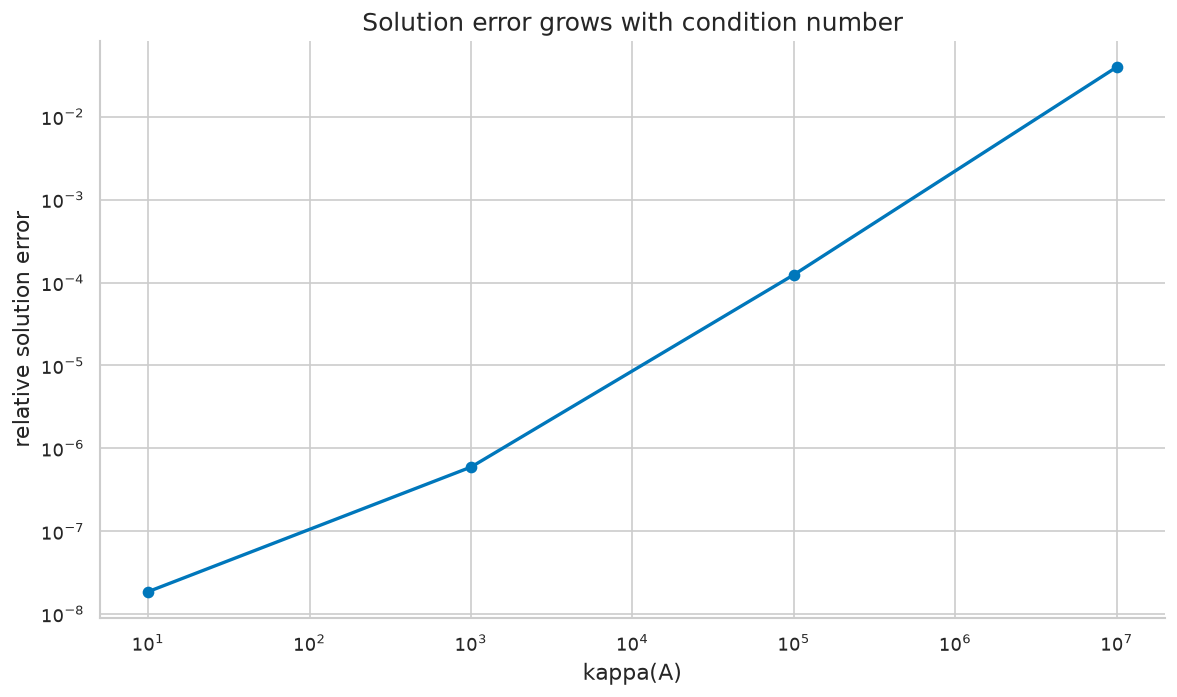

conditioning is a property of the problem, not the algorithm


In [19]:

rng = np.random.default_rng(42)
U, _ = la.qr(rng.normal(size=(5, 5))); V, _ = la.qr(rng.normal(size=(5, 5)))
kappas = [1e1, 1e3, 1e5, 1e7]; rel_errs = []
for kap in kappas:
    A = U @ np.diag(np.logspace(0, -np.log10(kap), 5)) @ V.T
    x_true = rng.normal(size=5); b = A @ x_true
    db = 1e-8 * la.norm(b) * rng.normal(size=5)
    x_pert = la.solve(A, b + db)
    rel = la.norm(x_pert - x_true) / la.norm(x_true); rel_errs.append(rel)
    check_true(f"kappa={kap:.0e}: relative error <= kappa * relative perturbation (slack 10x)", rel <= 10 * kap * (la.norm(db) / la.norm(b)))
fig, ax = plt.subplots()
ax.loglog(kappas, rel_errs, marker='o', color=WONG[0])
ax.set_title("Solution error grows with condition number"); ax.set_xlabel("kappa(A)"); ax.set_ylabel("relative solution error")
plt.tight_layout(); plt.show()
print("conditioning is a property of the problem, not the algorithm")

---

## What to Remember

- $Ax=b$ is a question about **column-space membership** and **null-space freedom**.
- Elimination is the fastest way to see consistency, pivots, and free variables.
- Least squares is projection, not just a formula.
- Conditioning governs sensitivity; stability governs how much extra numerical trouble your algorithm adds.
- Newton, KKT systems, DEQs, Gaussian processes, and second-order optimizers all reduce to repeated linear-system solves.

If you understand systems of equations at this level, you understand a large part of why modern AI computation looks the way it does.

## References and Learning Sources

- MIT 18.06 Linear Algebra: [https://web.mit.edu/18.06/www/](https://web.mit.edu/18.06/www/)
- Stanford EE263, *Introduction to Linear Dynamical Systems*: [https://stanford.edu/class/ee263/](https://stanford.edu/class/ee263/)
- Netlib, *Templates for the Solution of Linear Systems*: [https://www.netlib.org/templates/templates.html](https://www.netlib.org/templates/templates.html)
- UIUC CS 357 course materials on linear systems and conditioning: [https://courses.grainger.illinois.edu/cs357/](https://courses.grainger.illinois.edu/cs357/)
- Jonathan Shewchuk, *An Introduction to the Conjugate Gradient Method Without the Agonizing Pain*: [https://www.cs.cmu.edu/~quake-papers/painless-conjugate-gradient.pdf](https://www.cs.cmu.edu/~quake-papers/painless-conjugate-gradient.pdf)
- Ashish Vaswani et al., *Attention Is All You Need* (2017): [https://arxiv.org/abs/1706.03762](https://arxiv.org/abs/1706.03762)
- Shaojie Bai, J. Zico Kolter, Vladlen Koltun, *Deep Equilibrium Models* (2019): [https://arxiv.org/abs/1909.01377](https://arxiv.org/abs/1909.01377)
- James Martens and Roger Grosse, *K-FAC* (2015): [https://proceedings.mlr.press/v37/martens15.html](https://proceedings.mlr.press/v37/martens15.html)
- Vineet Gupta et al., *Shampoo* (2018): [https://proceedings.mlr.press/v80/gupta18a.html](https://proceedings.mlr.press/v80/gupta18a.html)
- Nikhil Vyas et al., *SOAP* (2024): [https://arxiv.org/abs/2409.11321](https://arxiv.org/abs/2409.11321)
- Maziar Raissi, Paris Perdikaris, George Karniadakis, *Physics-Informed Neural Networks* (2019): [https://www.sciencedirect.com/science/article/pii/S0021999118307125](https://www.sciencedirect.com/science/article/pii/S0021999118307125)
- Jupyter documentation on notebooks as narrative documents: [https://docs.jupyter.org/en/latest/use/use-cases/nb_as_docs.html](https://docs.jupyter.org/en/latest/use/use-cases/nb_as_docs.html)